# 大模型微调 03：Prompt-Tuning、参数高效微调与提示词工程

本篇整理所有已下载的 `03` 开头资料：`03-笔记/Day03 笔记.md`、`03-课件` 下的 Prompt-Tuning 与金融提示词工程课件，以及 `03-软件安装/Ollama大模型高效管理工具.md`。课程主线从参数高效微调出发，延伸到大模型提示词应用和本地 Ollama 调用。

> 阅读顺序：先回顾模型与 NLP 范式，再学习 Prompt/PET/P-Tuning/Prefix/Adapter/LoRA，最后把这些方法放进金融分类、抽取、匹配和本地模型调用中。


## 一、Qwen 与 Baichuan：本章模型背景

### 1.1 Qwen

Qwen 是阿里巴巴训练并开源的一系列大语言模型，课程资料介绍了从 1.8B 到 72B 等不同规模。训练目标是根据已有上文预测下一个词，整体采用 Decoder-only Transformer。

- 使用 GQA（Grouped-Query Attention）减少 KV cache，提升推理效率；
- 使用 SwiGLU 激活函数；
- 使用 RoPE 旋转位置编码；
- 使用 RMSNorm 稳定训练。

| 配置 | Qwen-7B-Instruct |
| --- | ---: |
| 参数量 | 7B |
| 隐藏层维度 | 3584 |
| 层数 | 28 |
| 注意力 | 28 个 query、4 个 key-value |
| 训练数据 | 1.2T |
| 词表大小 | 151936 |
| 最大长度 | 32768 |


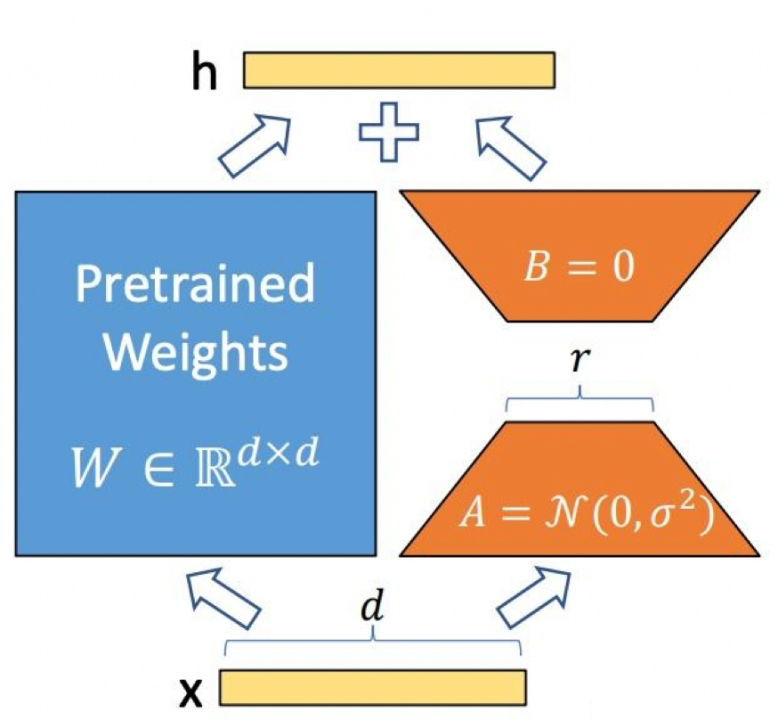

### 1.2 Baichuan-7B

Baichuan-7B 由百川智能发布，支持中英双语，使用约 1.2T token 训练，词表大小 64000，数据包含开源中英文数据、中文互联网数据和高质量知识数据。

它与 LLaMA 类似，也是 Decoder-only 架构，采用 Pre-LayerNorm + RMSNorm、SwiGLU 和 RoPE。

| 配置 | 数值 |
| --- | ---: |
| 参数量 | 7B |
| 隐藏层维度 | 4096 |
| 层数 | 32 |
| 注意力头数 | 32 |
| 训练数据 | 1.2T |
| 词表大小 | 64000 |
| 最大长度 | 4096 |


## 二、NLP 任务的四种范式

课程将 NLP 的发展概括为四个阶段：

1. **传统机器学习**：TF-IDF 特征 + 朴素贝叶斯等算法，需要较多特征工程。
2. **深度学习模型**：Word2Vec + LSTM 等，减少手工特征工程，准确率进一步提升。
3. **预训练模型 + Fine-Tuning**：先在大规模语料预训练，再在小规模任务数据上微调，例如 BERT + Fine-Tuning。
4. **预训练模型 + Prompt + 预测**：通过模板、指令和示例把下游任务改写成模型熟悉的预训练形式，减少标注数据和参数更新。

整体趋势是从更依赖监督和任务专用结构，发展到少监督甚至零样本的任务适配。


## 三、Prompt-Tuning 入门

### 3.1 Fine-Tuning 的痛点

Fine-Tuning 是一种迁移学习：在通用语料上训练好的模型，继续使用任务数据训练，使它适应分类、匹配、抽取等下游任务。它的问题包括：

- 下游目标和预训练目标差距较大；
- 小数据集微调容易过拟合；
- 每个任务都需要标注语料；
- 大模型全参数更新的显存、时间和存储成本很高。

Prompt-Tuning 的思路是让下游任务去适应预训练任务，通过添加模板把任务改写成模型熟悉的 Masked LM 或生成任务。


### 3.2 一个情感分类例子

原句：

```text
[CLS] I like the Disney films very much. [SEP]
```

传统 Fine-Tuning 会取 `[CLS]` 表征，再接一个新 MLP 分类器。Prompt-Tuning 则构造带 `[MASK]` 的模板：

```text
[CLS] I like the Disney films very much. [SEP] It was [MASK]. [SEP]
```

输入 BERT 后，直接复用预训练好的 MLM head 预测 `[MASK]`。然后使用 Verbalizer 把词映射为类别：`great → positive`，`terrible → negative`。训练时只关心指定 label word 的概率，并使用交叉熵优化。


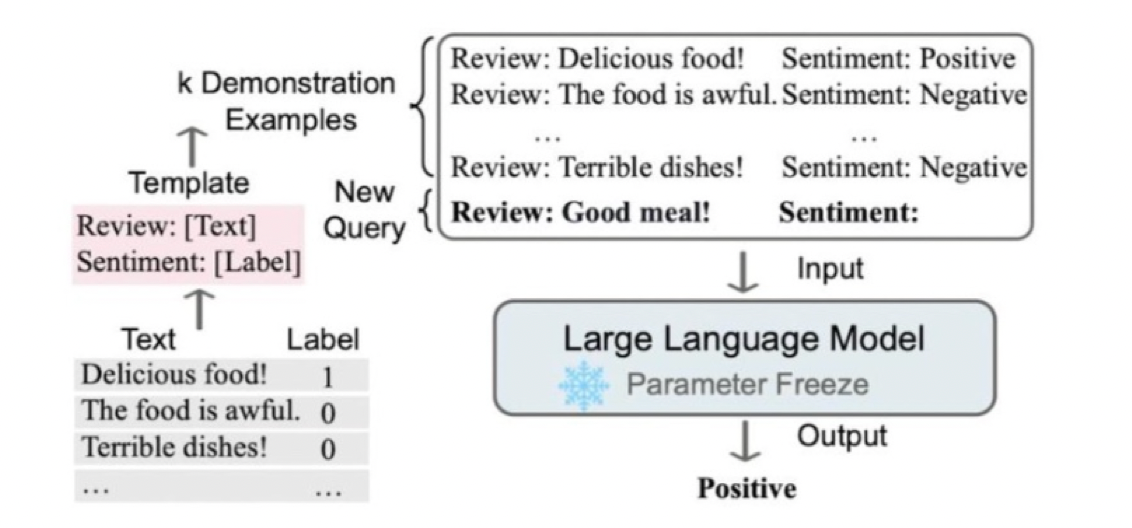

### 3.3 PET：Pattern + Verbalizer

PET（Pattern-Exploiting Training）把分类任务转换为完形填空，两个核心组件是：

- **Pattern / Template**：带 `[MASK]` 的任务模板 `T`。
- **Verbalizer**：把预测出的 label word 映射到真实类别 `V`。

不同任务、样本适合不同 Pattern 和 Verbalizer。人工设计成本高，而且模板中只改一个词都可能导致结果明显变化，人工方案不一定最优，Prompt-Tuning 与原始 MLM 的语义和分布也可能存在差异。


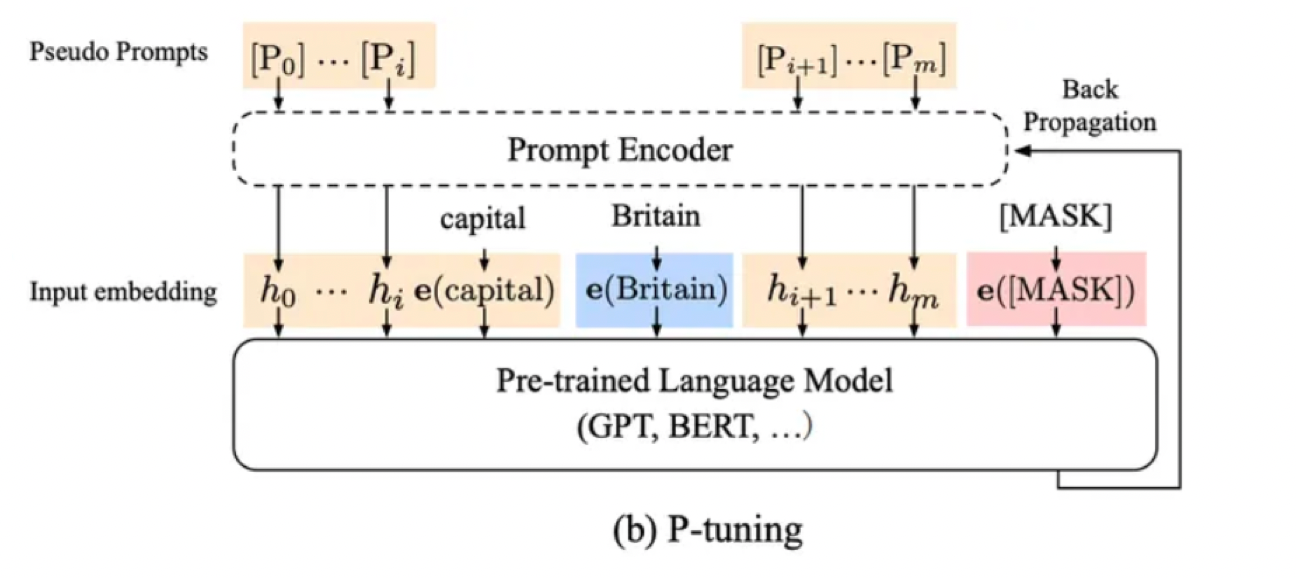

### 3.4 Hard Prompt 与 Soft Prompt

- **Hard Prompt（离散提示）**：直接在输入中写入真实文本模板，容易理解，但依赖人工设计，模板词语变化可能导致结果波动。
- **Soft Prompt（连续提示）**：把模板中的伪 token 表示为可训练向量，例如 `T=[x],[v₁],[v₂],...,[vₙ],[MASK]`。这些伪 token 没有固定文本含义，训练时只更新对应的向量参数，预训练模型主体保持冻结。

Soft Prompt 让模型在连续语义空间中自动寻找更合适的提示表示，减少了人工枚举模板的成本。


## 四、P-Tuning、Prompt Tuning 与 Prefix/Adapter/LoRA

### 4.1 Prompt Tuning（更偏 NLG）

Google 在 *The Power of Scale for Parameter-Efficient Prompt Tuning* 中提出 Prompt Tuning：为每个输入增加固定长度的可训练前缀提示，冻结大模型参数，只更新 prompt embedding。输入 token 的 embedding 与 prompt embedding 拼接后送入模型，训练过程中只更新 prompt 部分。

优点是附加参数很少，模型足够大时效果可以接近全参数微调；缺点是小样本场景表现较弱、收敛较慢、调参复杂。


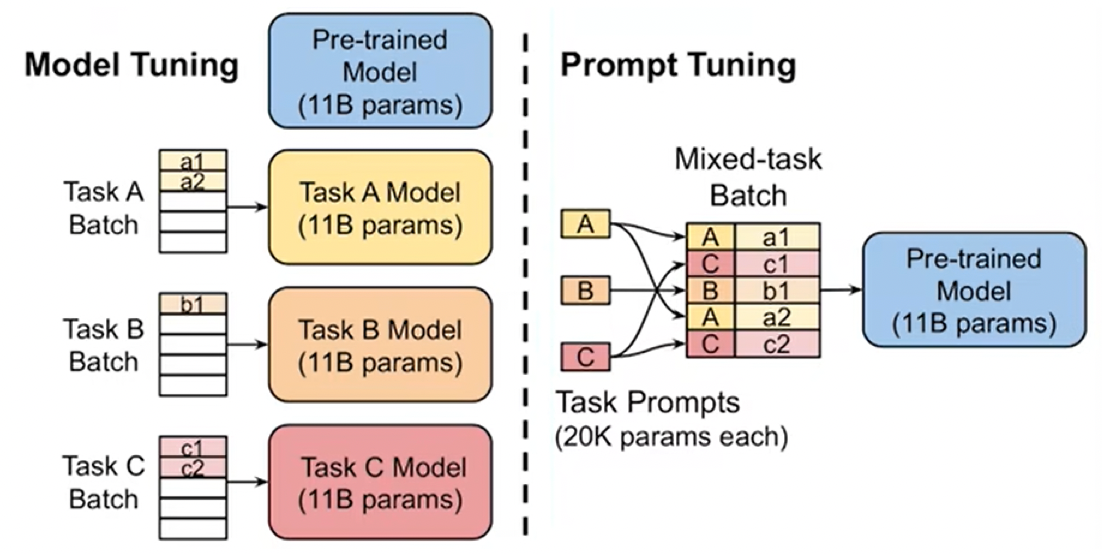

### 4.2 P-Tuning V1 / V2（更偏 NLU）

P-Tuning 由清华论文 *GPT Understands, Too* 提出，动机是 Prompt 构造方式会严重影响效果。它不直接用随机可训练 embedding，而是使用 LSTM + MLP 对 prompt embedding 做编码，利用上下文关系改善初始化；LLM 参数保持冻结，训练完成后只保留 prompt 编码后的向量。

P-Tuning V2 进一步在模型的每一层加入连续 prompt，并优化这些 prompt 参数，主要解决 V1 在小参数模型上的效果问题。


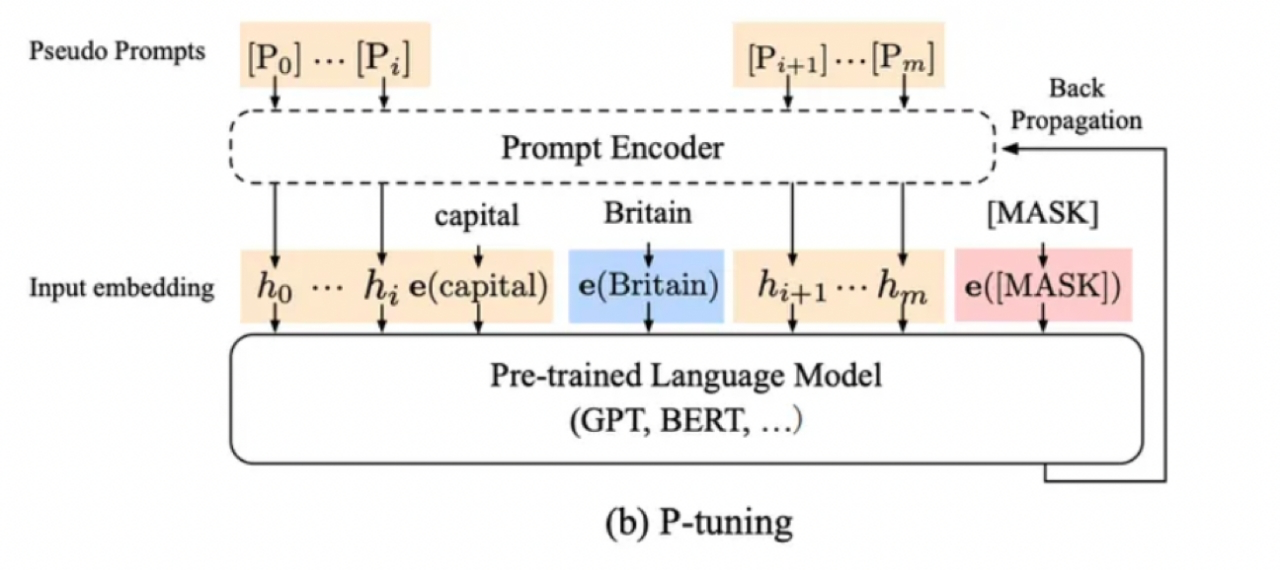

### 4.3 Prefix-Tuning

Prefix-Tuning 在输入 token 前构造任务相关的 virtual tokens：`z=[Prefix,x,y]`，训练时只更新 Prefix，Transformer 其他参数冻结。为了让训练更稳定，Prefix 前加入 MLP，将较小输入映射成每层需要的前缀表示，训练结束后只保留 Prefix 参数。

与 P-Tuning 的区别：Prefix-Tuning 的可训练 embedding 位于输入开头，并且每层都添加参数、用 MLP 初始化；P-Tuning 的位置不固定，使用 LSTM + MLP 初始化。Prompt Tuning 可以看作 Prefix-Tuning 的简化版本，只在输入层加入 prompt token，不再使用 MLP 调整。


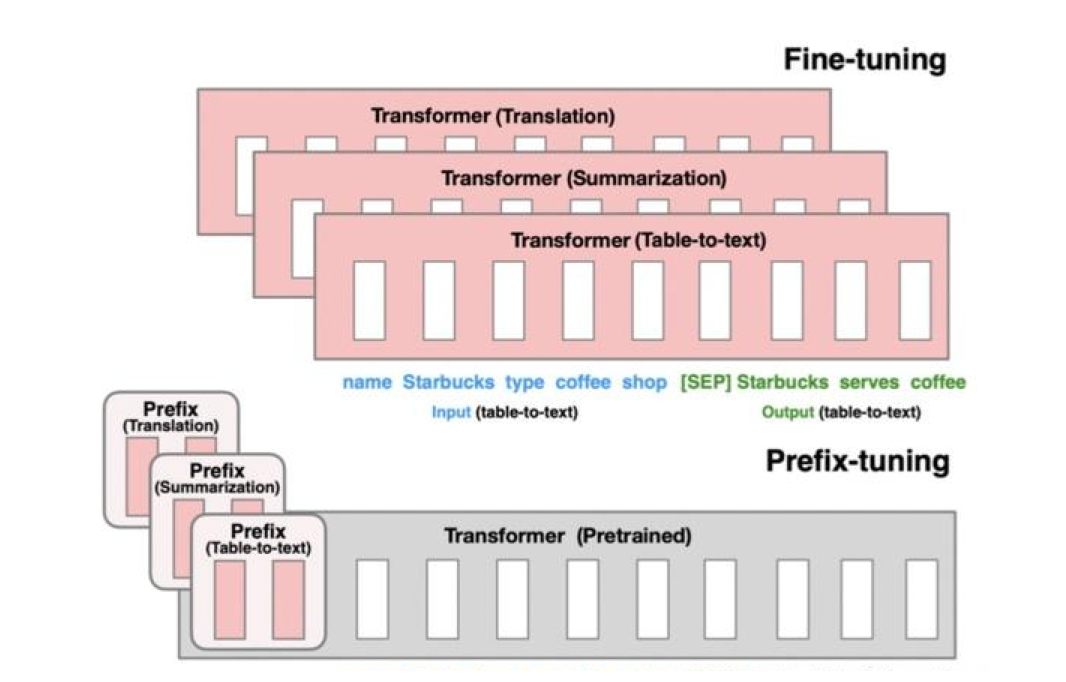

### 4.4 Adapter Tuning

Adapter 不在输入前添加参数，而是在预训练模型内部层之间插入小模块。训练时冻结原模型，只更新 Adapter：

1. `down-project`：把高维特征降到低维；
2. 非线性变换；
3. `up-project`：映射回原始维度；
4. 加上 skip connection，最差情况下可以退化为 identity。

它的参数量小，但额外模块会引入推理计算和延迟。


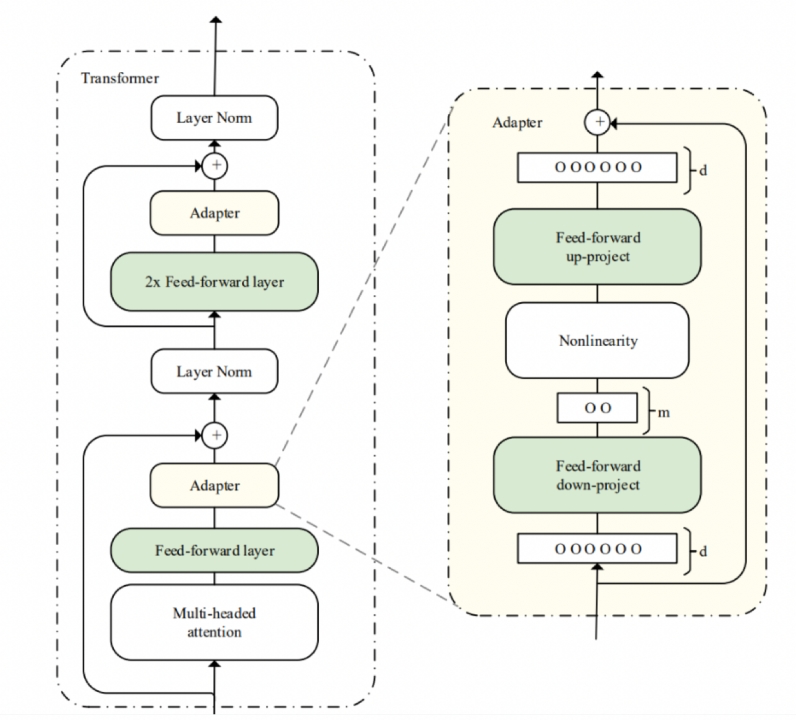

### 4.5 LoRA：低秩适应

LoRA（Low-Rank Adaptation）冻结预训练权重，在 Linear 层旁增加低秩旁支。原始权重更新 `ΔW` 不直接学习，而是分解为：

\[
\Delta W = W_A W_B
\]

其中 `W_A` 将 `d` 维降到秩 `r`，`W_B` 再从 `r` 维升回 `d` 维，`r` 远小于 `d`；`W_B` 初始化为 0，使训练开始时旁支不会改变原模型输出。训练完成后，可以将低秩更新合并到原始权重，推理时不再引入额外分支。

LoRA 解决了 Adapter 的推理延迟和 Prefix 占用上下文长度等问题，是目前最常用的参数高效微调方法之一。


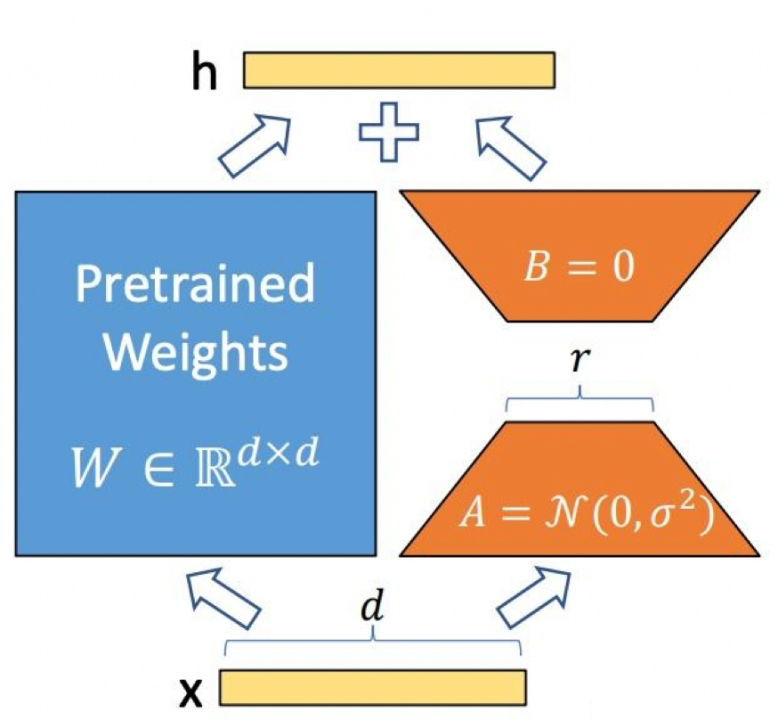

LoRA 的伪代码：

```python
input_dim = 768
output_dim = 768
rank = 8
W = ...
W_A = nn.Parameter(torch.empty(input_dim, rank))
W_B = nn.Parameter(torch.empty(rank, output_dim))

nn.init.kaiming_uniform_(W_A, a=math.sqrt(5))
nn.init.zeros_(W_B)

def lora_forward_matmul(x, W, W_A, W_B, alpha):
    h = x @ W
    h += x @ (W_A @ W_B) * alpha
    return h
```


### 4.6 PEFT 方法的选择

| 方法 | 可训练部分 | 主要适用方向 | 关键特点 |
| --- | --- | --- | --- |
| Prompt Tuning | 输入 prompt embedding | 大模型、生成任务 | 简单、参数少，但小模型收敛较慢 |
| P-Tuning | prompt embedding + LSTM/MLP | NLU | prompt 位置灵活 |
| Prefix-Tuning | 每层 Prefix | 生成任务 | 需要 MLP 初始化，表达能力强 |
| Adapter | 层间小模块 | 多任务/模块化适配 | 参数少，但有推理延迟 |
| LoRA | 低秩矩阵 A、B | 通用微调 | 参数、显存和存储开销低，可合并权重 |


## 五、超大模型 Prompt 方法：ICL、Instruction 和 CoT

### 5.1 In-Context Learning

ICL 最早在 GPT-3 中提出：从训练数据中挑选少量标注样本，将任务描述和示例放进当前输入，模型不更新参数，只根据上下文完成测试样本。

- Zero-shot：任务说明 + 测试样本；
- One-shot：任务说明 + 1 个示例 + 测试样本；
- Few-shot：任务说明 + 多个示例 + 测试样本。


### 5.2 Instruction-Tuning

Prompt 更像是激发模型的补全能力；Instruction 则用更明确的指令激发模型的理解能力和执行能力。例如让模型不只是补全“这家餐厅太 __ 了”，而是明确告诉它“判断这句话的情感，选项 A=好、B=一般、C=差”。

Instruction-Tuning 通常为不同任务设计多种指令模板，并用任务数据进行微调，让模型学会理解指令模式。没有精调的模型也能在 Prompt 下完成部分任务，但 Instruction-Tuning 需要模型在训练阶段见过这类指令。


### 5.3 Chain-of-Thought

思维链（Chain-of-Thought，CoT）是在复杂算术、常识和符号推理中加入中间推导步骤的提示策略。它是 ICL 的一种特殊形式：

- **Few-shot CoT**：把示例从 `<input, output>` 扩展为 `<input, reasoning steps, output>`；
- **Zero-shot CoT**：先用“Let's think step by step”让模型产生推导，再用“Therefore, the answer is”得到答案。

高质量思维链应具备逻辑性、全面性、可行性和可验证性。它更依赖模型规模，规模太小时不一定有效。


## 六、金融领域的提示词应用

03 课件以 Qwen/ChatGLM 等模型为例，把金融应用拆成三类任务：分类、信息抽取和文本匹配。共同方法是：明确任务定义、给出 few-shot 示例、规定输出格式，再调用模型做预测。

### 6.1 金融文本分类

将文本分类为“新闻报道、公司公告、财务公告、分析师报告”等类别。Prompt 要告诉模型什么是分类任务，列出允许的类别，并给出 User/Bot 示例：输入一段文本，输出一个类别。示例中的 Bot 回复由人工提供，用来约束模型的判断方式。

### 6.2 金融信息抽取

先定义 Schema，例如：

```python
schema = {'金融': ['日期', '股票名称', '开盘价', '收盘价', '成交量']}
```

Prompt 要求模型从股票文本中抽取这些实体，并严格按 JSON 输出；原文未出现的字段统一输出 `['原文中未提及']`，多个值用逗号分隔。实际代码通常需要 `clean_response()` 做结果清洗，再进行解析。

### 6.3 金融文本匹配

给模型两句话，判断是否表达相似语义，输出“相似/不相似”。同样使用 few-shot 示例固定判断口径和输出格式。

### 6.4 项目环境

金融项目课件使用 Python 3.8 以上，依赖包括 `protobuf>=3.19.5,<3.20.1`、`transformers>=4.26.1`、`icetk`、`cpm_kernels` 和 `streamlit==1.17.0`。ChatGLM-6B 约需 12GB 以上磁盘空间，加载约需 13GB 显存，不足时需要量化。


## 七、提示工程指南

提示工程是在不修改模型权重的情况下，通过精心设计上下文引导模型行为。课件强调两条总原则：**指令要清晰明确，给模型足够的思考时间。**

### 7.1 构造清晰指令的技巧

- 提供任务、上下文、约束和期望结果，不能只给一句模糊要求；
- 使用分隔符（```、三引号、XML 标签等）区分指令和待处理文本，减少混淆；
- 要求 JSON、HTML、Markdown 或固定字段等结构化输出，便于程序解析；
- 给出一两个参考示例，让模型学习任务含义和输出风格；
- 让模型扮演明确角色，例如 AI 面试官、金融分析师或文本校对员。


### 7.2 让模型充分思考

复杂任务不应要求模型立刻给结论，可以在 Prompt 中拆分步骤：先总结，再翻译，再抽取名称，最后输出 JSON。对于计算或答案判断任务，还可以要求模型先独立求解，再与给定答案比较，最后给出判断。

示例结构：

```text
步骤：
1. 先独立解决问题；
2. 将你的解法与学生解法逐项比较；
3. 比较关键数值是否一致；
4. 输出“正确/不正确”和理由。
```

这类分步约束的目的，是让模型有足够的推理过程来检查错误，而不是为了展示冗长的回答。


### 7.3 Prompt 迭代优化

一次写出完美 Prompt 很难，建议使用循环：

1. 写一个清晰的初版 Prompt；
2. 输入模型，观察结果；
3. 分析遗漏、冗余、受众不匹配和格式错误；
4. 增加限制、受众、字段或输出格式；
5. 重新测试，直到满足应用需求。

课件示例中，产品营销文案先出现文本过长，第一次迭代加入“最多 50 个词”；第二次迭代明确目标受众为家具零售商，强调材料、工艺和结构；第三次迭代要求输出产品 ID 和尺寸 HTML 表格。这个过程说明 Prompt 的优化应根据结果具体修改，而不是盲目增加描述。


### 7.4 常见文本任务模板

- **概括**：明确最大长度，例如“最多 30 个字”；
- **角度摘要**：指定关注物流、价格、质量或用户体验；
- **关键信息抽取**：使用 Extract，而不是让模型泛化总结；
- **翻译**：说明目标语言、语气和是否保留格式；
- **风格调整**：指定受众与正式/口语/商务风格；
- **格式转换**：指定输入格式、输出格式、表名和字段；
- **拼写语法纠错**：要求保持原语言，规定无错误时的返回值。


## 八、Ollama：本地运行和调用 LLM

### 8.1 安装与环境配置

Ollama 是用于本地运行和管理开源大模型的服务工具，支持 Windows、macOS 和 Linux。

1. 从 <https://ollama.com/> 下载 `OllamaSetup.exe` 并安装。
2. 安装后如果要修改模型目录，先退出右下角 Ollama；否则环境变量不会立即生效。
3. 可选：删除启动目录中的 `Ollama.lnk`，关闭开机自启动。
4. 新建环境变量：

```text
变量名：OLLAMA_MODELS
变量值：D:\Work\ollama\models
```

重新启动 Ollama 后，在 `ollama.exe` 所在目录打开终端，运行：

```bash
ollama run <模型名称>
```

7B 模型至少需要约 8GB 显存，13B 至少约 16GB；没有 GPU 时默认使用 CPU，有 GPU 时会优先使用 GPU。具体占用还取决于量化级别和上下文长度。


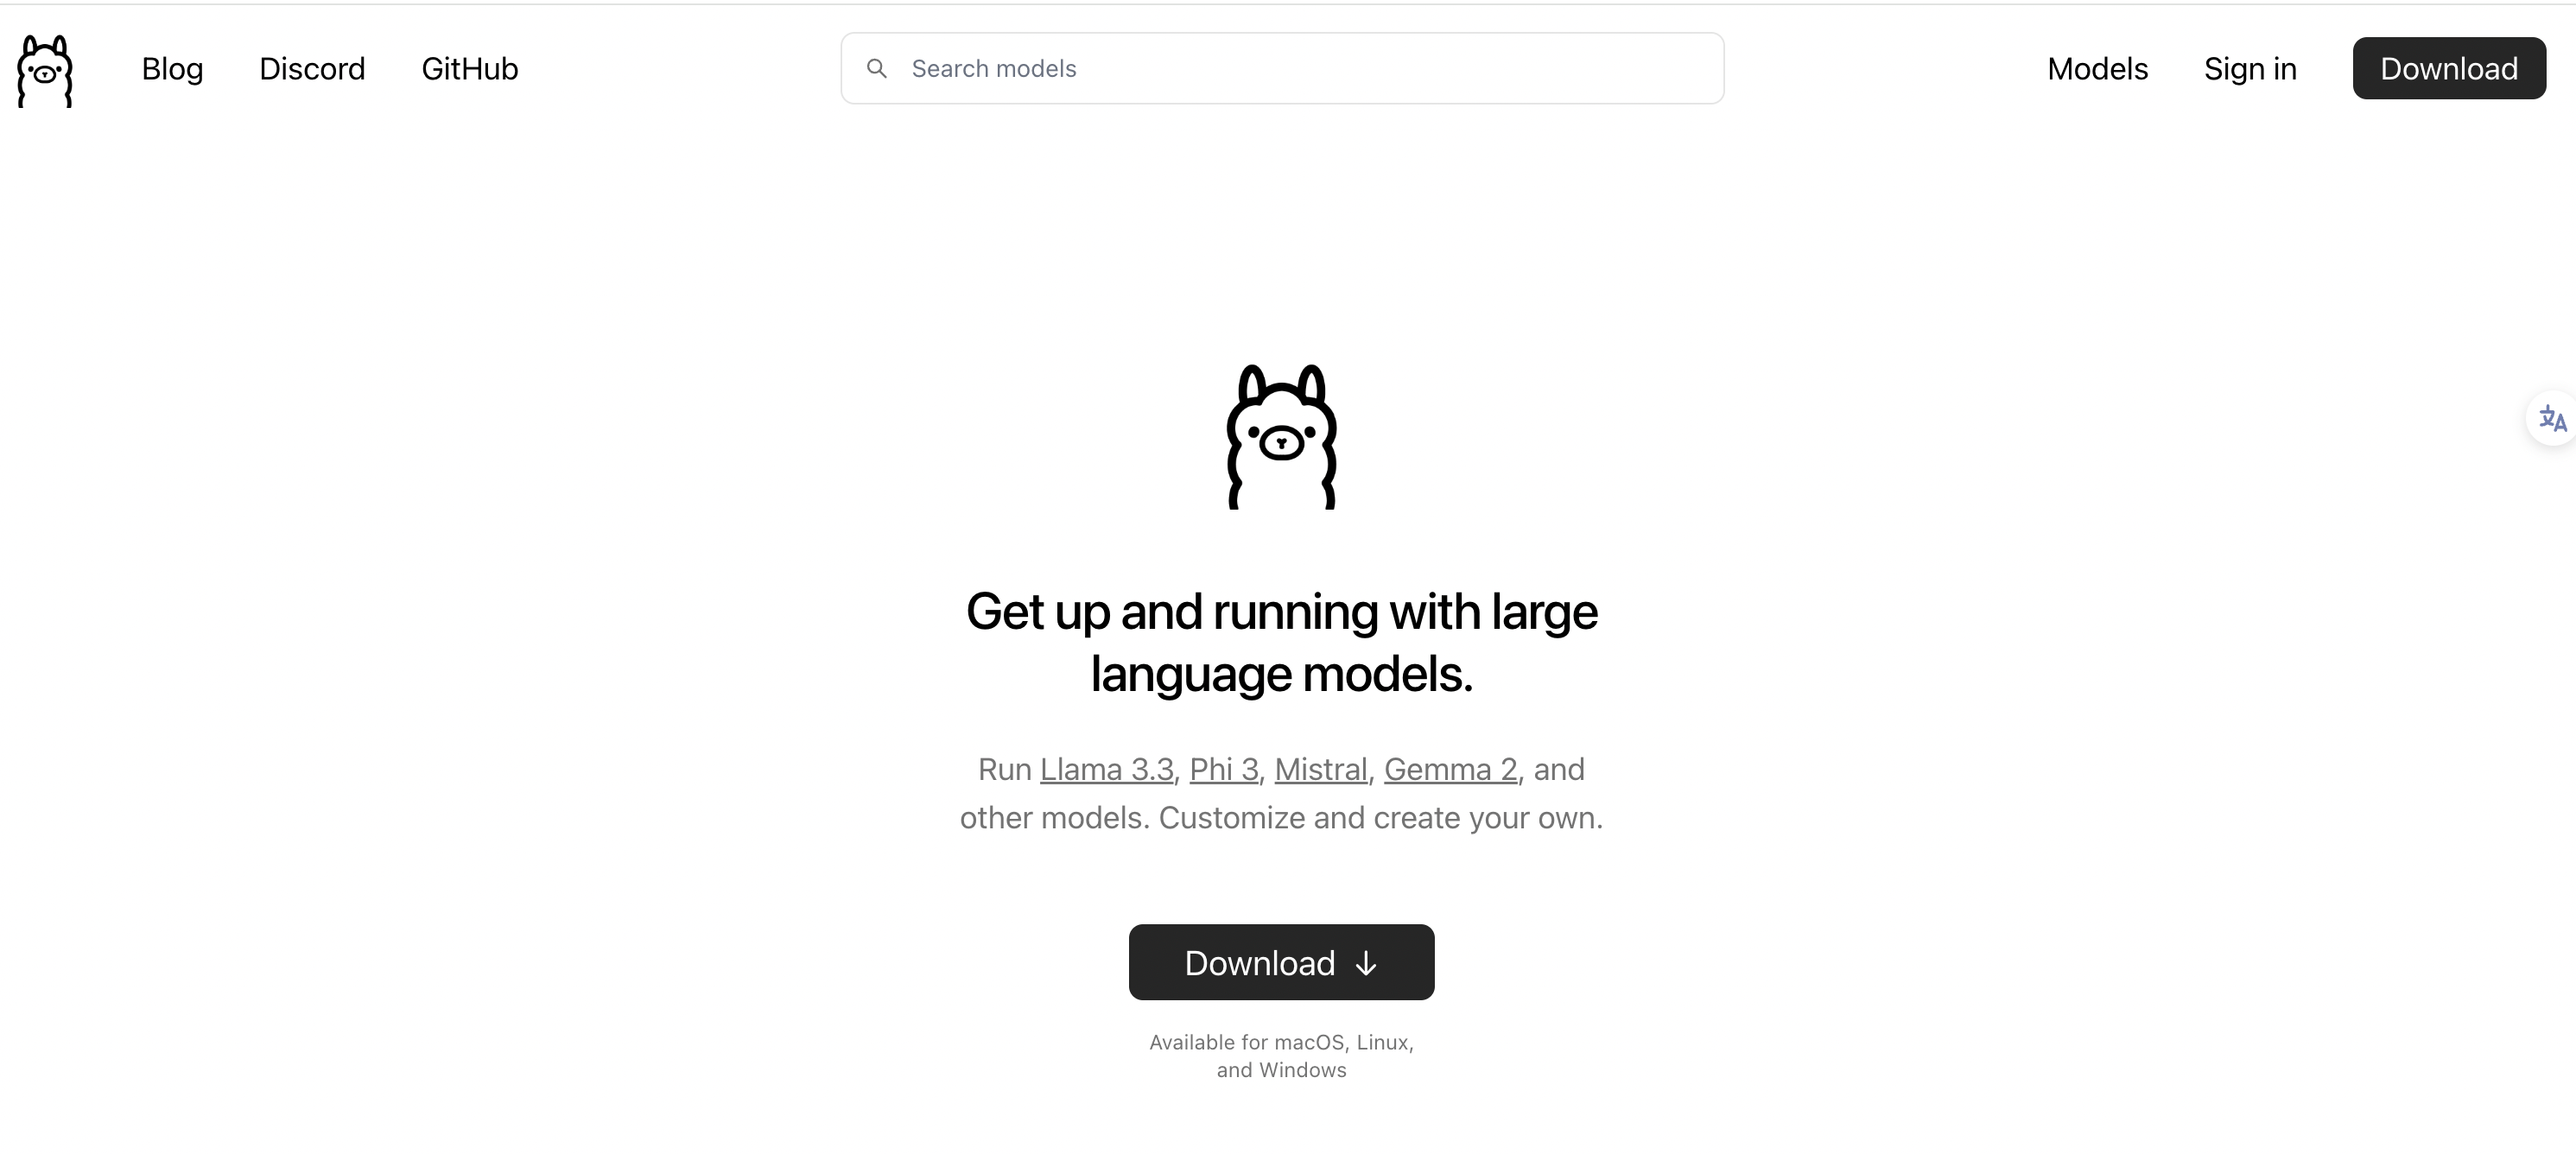

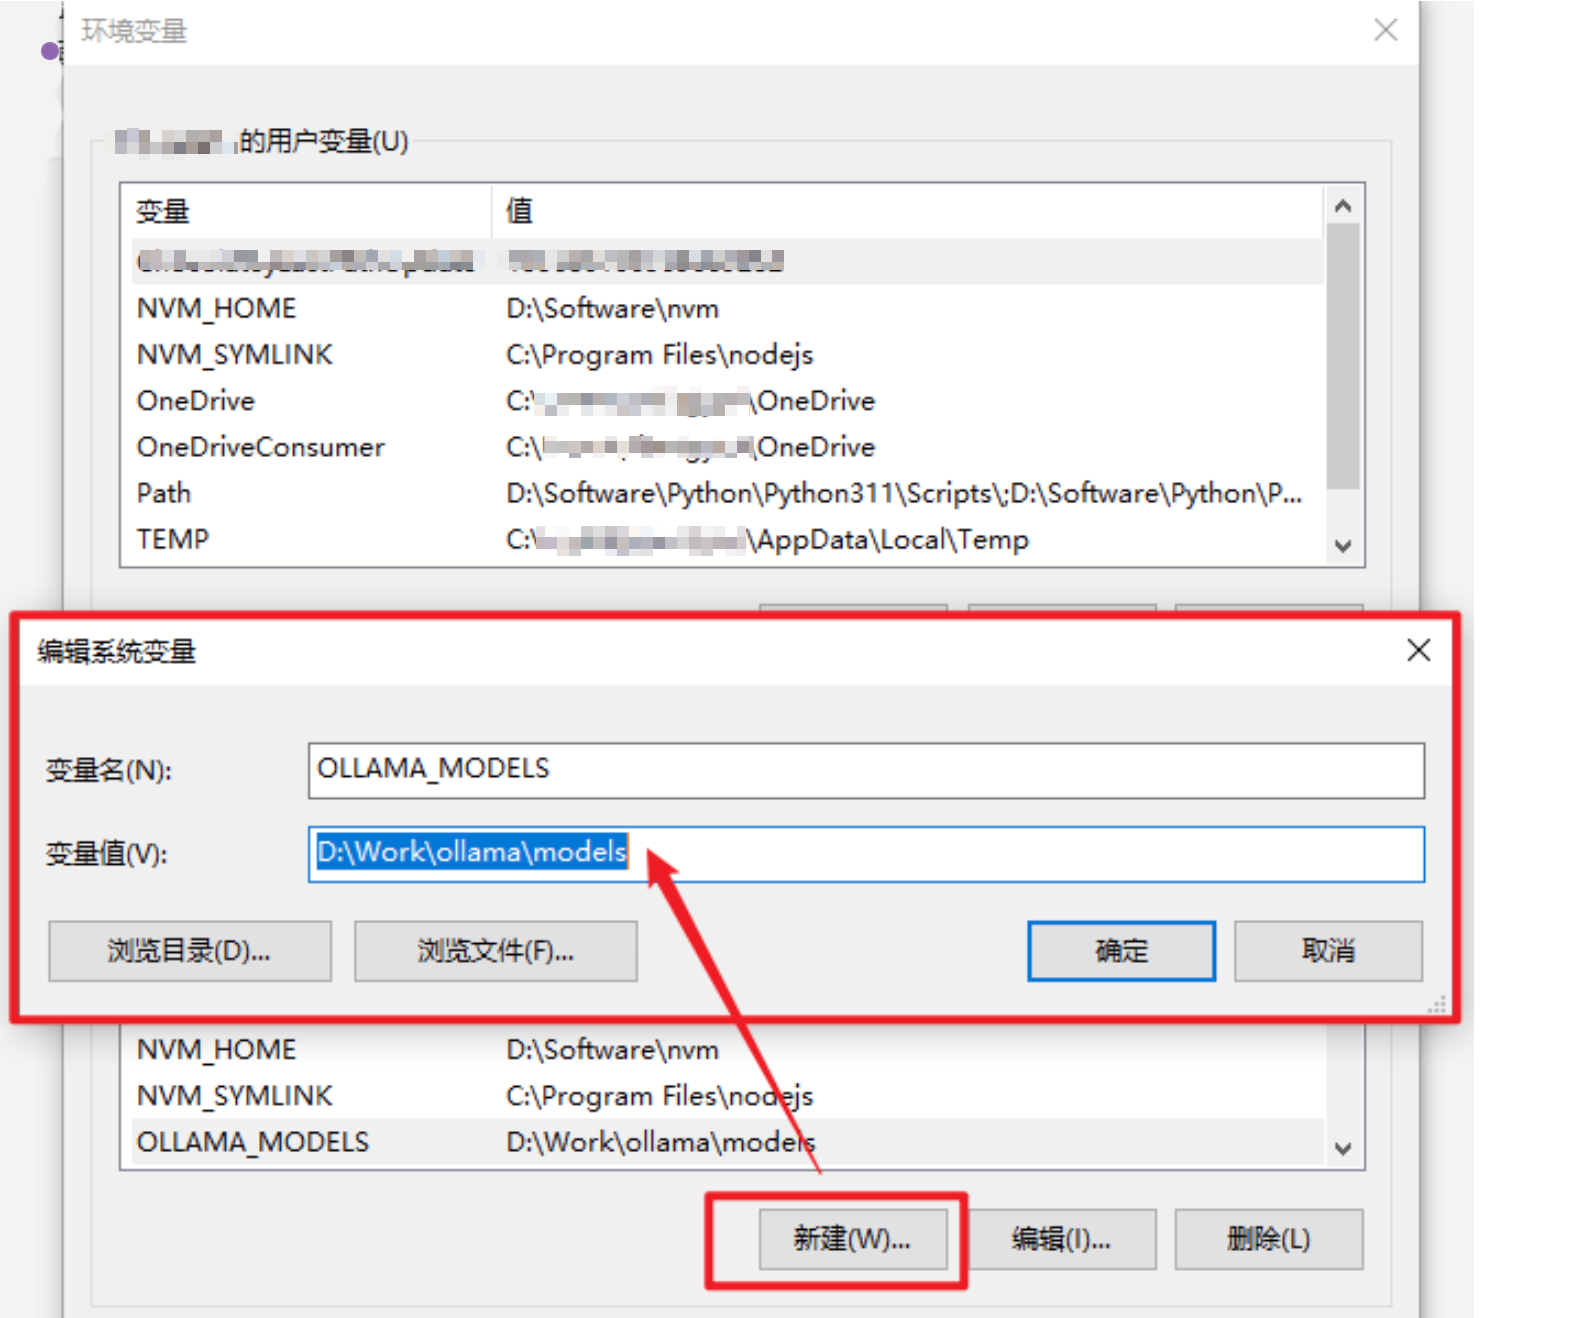

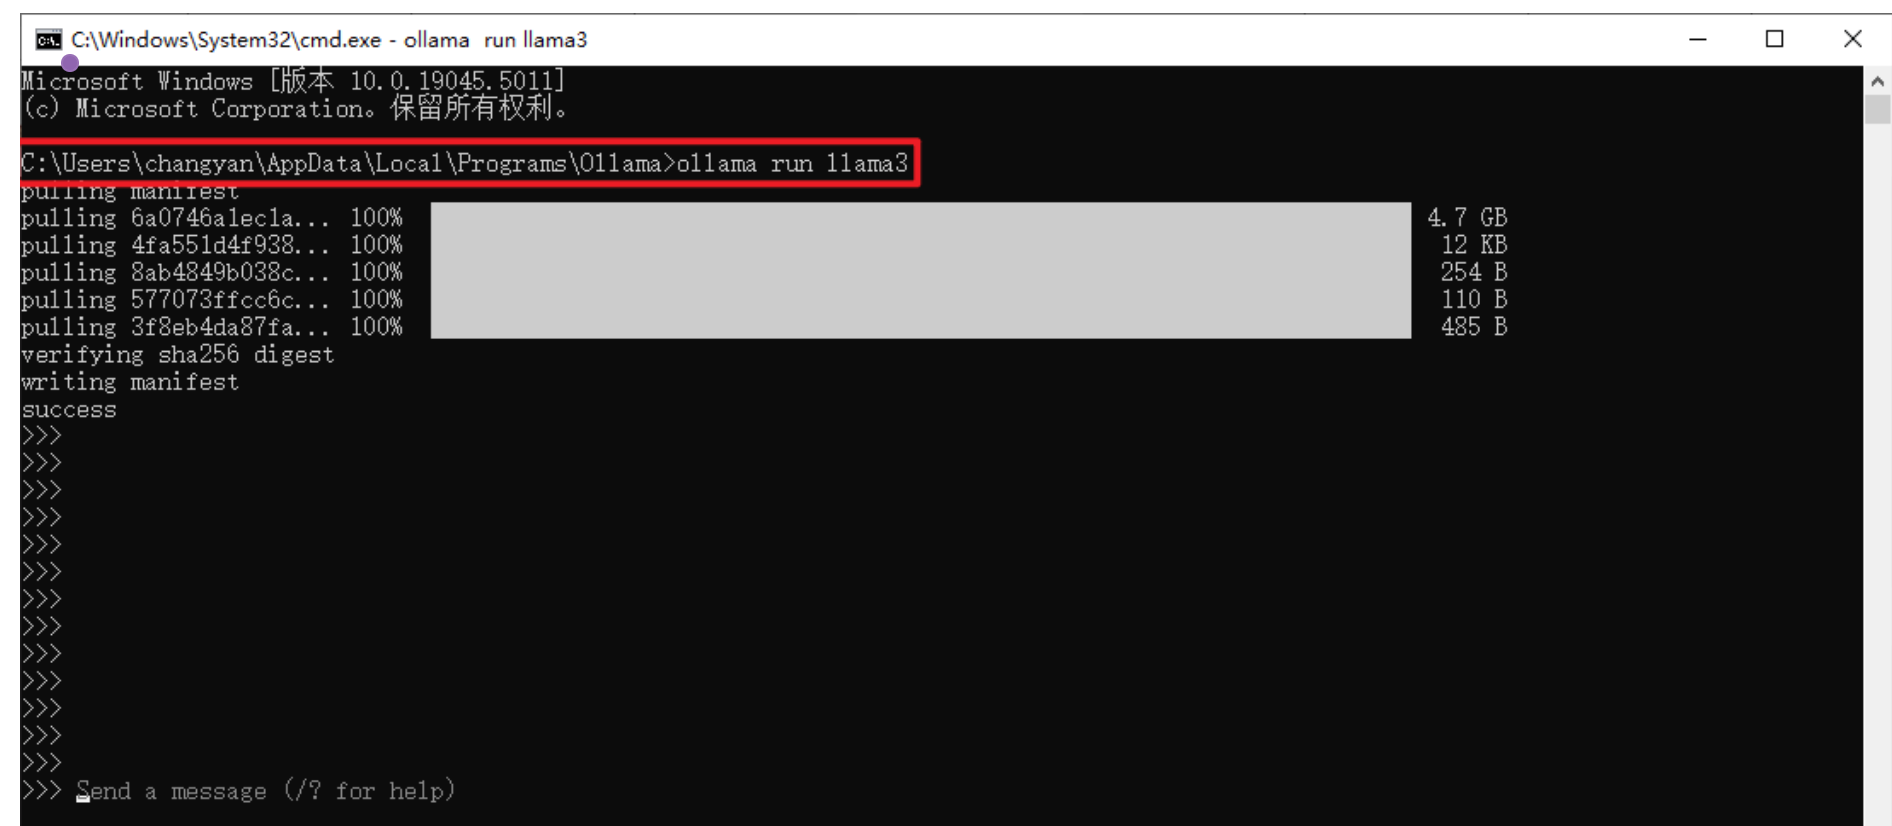

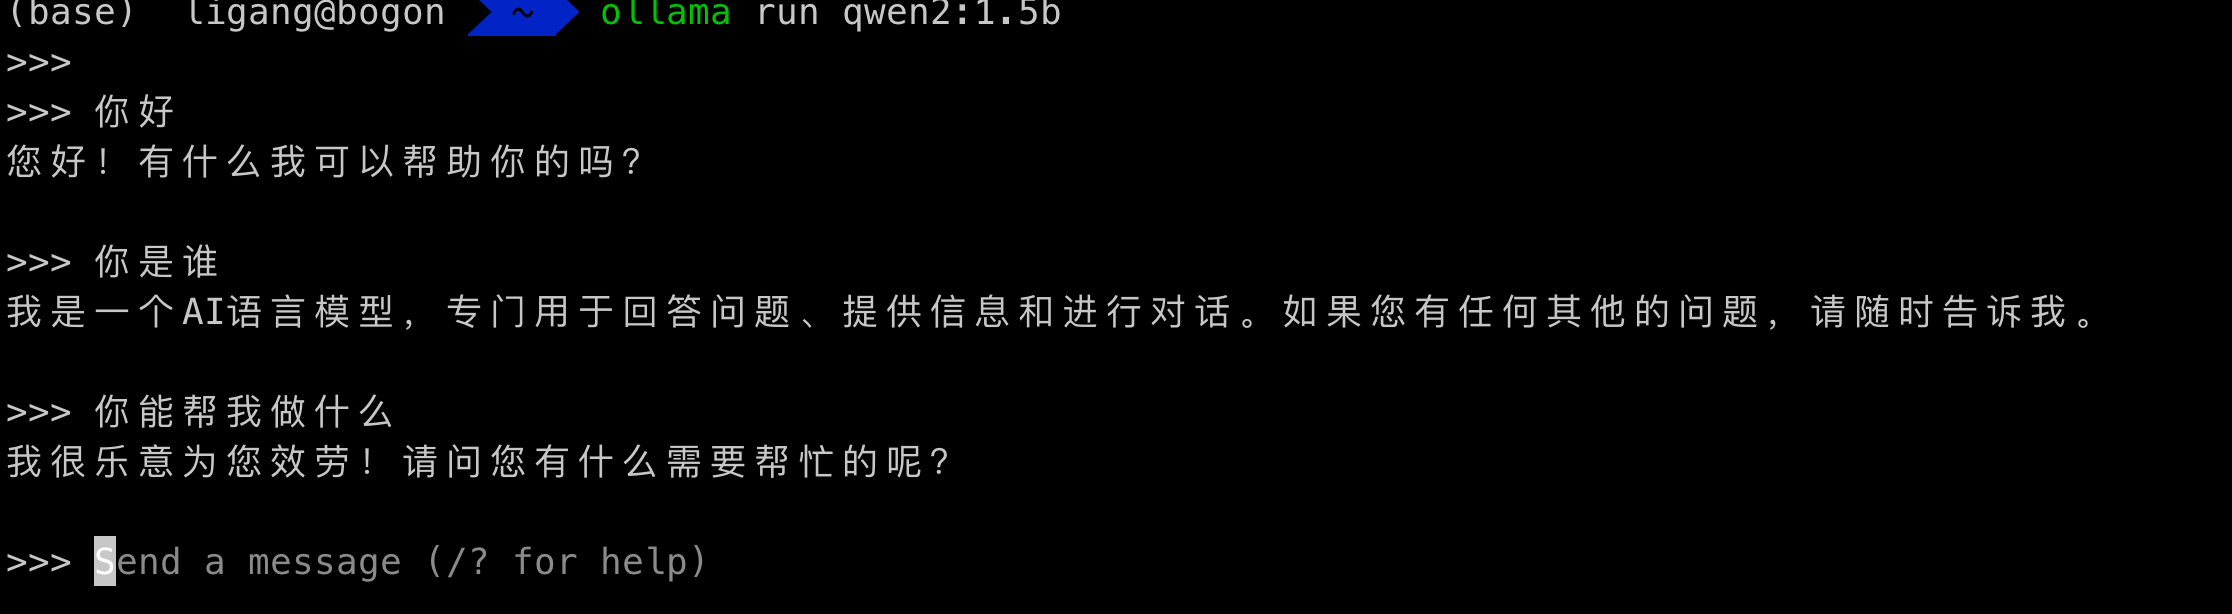

### 8.2 Python 调用 Ollama API

安装 Python 客户端：

```bash
pip install ollama
```

方式一：直接使用 `ollama.chat` 或 `ollama.generate`。

```python
import ollama

response = ollama.chat(
    model='qwen2:1.5b',
    messages=[{'role': 'user', 'content': '为什么天空是蓝色的？'}]
)
print(response['message']['content'])

# 生成式调用
# response = ollama.generate(model='qwen2:1.5b', prompt='为什么天空是蓝色的？')
```

方式二：使用 `Client` 访问本地或远程服务：

```python
from ollama import Client

client = Client(host='http://127.0.0.1:11434')
response = client.chat(
    model='qwen2:1.5b',
    messages=[{'role': 'user', 'content': '为什么天空是蓝色的？'}]
)
print(response['message']['content'])
```

方式三：开启流式输出：

```python
import ollama

stream = ollama.chat(
    model='qwen2:1.5b',
    messages=[{'role': 'user', 'content': '为什么天空是蓝色的？'}],
    stream=True,
)
for chunk in stream:
    print(chunk['message']['content'], end='', flush=True)
```


### 8.3 LangChain 和 requests 调用

LangChain 方式：

```bash
pip install langchain langchain_community
```

```python
from langchain_community.llms import Ollama

llm = Ollama(
    base_url='http://127.0.0.1:11434',
    model='qwen2:1.5b',
    temperature=0,
)
res = llm.invoke('你是谁')
print(res)
```

直接调用 HTTP API：

```python
import requests

url = 'http://127.0.0.1:11434/api/chat'
data = {
    'model': 'qwen2:1.5b',
    'options': {'temperature': 0.0},
    'stream': False,
    'messages': [{'role': 'system', 'content': '你是谁？'}],
}
response = requests.post(url, json=data, headers={'Content-Type': 'application/json'}, timeout=60)
print(response.json())
```

`temperature=0` 会让输出相对稳定；开启 `stream=True` 则需要逐段读取生成结果。


## 九、本章总结

- Prompt-Tuning 把下游任务改写成预训练模型擅长的补全或生成任务，减少全参数微调的成本。
- PET 依赖 Pattern 和 Verbalizer；Hard Prompt 依赖人工模板，Soft Prompt 学习连续向量。
- P-Tuning、Prefix-Tuning、Adapter 和 LoRA 都是 PEFT 方法，区别在于可训练参数放在输入、每层前缀、内部模块还是低秩矩阵。
- 超大模型常用 ICL、Instruction 和 CoT；金融应用要把任务、示例、Schema 和输出格式写清楚。
- Prompt 工程需要清晰指令、分隔符、结构化输出、参考示例、角色和迭代优化。
- Ollama 把本地模型运行、模型目录管理和 Python/LangChain/HTTP 调用串起来，是后续本地大模型应用的基础环境。
